# Question 3.(g).iv and 3.(g).v: exploration

Notebook to explore the results of the battery case step by step. It is **not submitted** (the `notebooks/`
folder is removed before submission): everything used in the report comes from `python main.py --question Q3_battery`,
and this notebook calls the same functions.

1. (iv) Base case with and without the battery
2. (v) Sensitivity sweeps (the ones of `main.py`, plus a cell to try other values)
3. End of the day: our $\pi^{end}$ against the alternatives, and a fine sweep of $\pi^{end}$
4. Extended-horizon benchmark (35 h) and the value of the stored energy
5. Notes

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from main import Q3_BATTERY_SWEEPS, battery_run, end_of_day_tables, schedule_change
from src.data_loader import load_question
from src.model import FlexibleConsumerModel, solve_extended_horizon, terminal_value
from src.plotting import plot_battery_schedule, plot_battery_sensitivity

pd.set_option("display.precision", 3)
B = load_question("Q3_battery")      # with the battery
NB = load_question("Q3")             # the same consumer without the battery (3.(d))
p_imp = B.energy_price + B.import_tariff
eta_ch = B.battery_charging_efficiency
print(B.summary())

Case                 : Q3_battery
Consumer             : C_03_BAT
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.41 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : None
Min daily energy     : 40.0
Reference profile    : yes (32.3 kWh/day)
Disutility lin/quad  : None / 1.0
Battery              : 4.0 kWh, 1.5/1.5 kW, eta 0.95/0.95, initial SoC 2.0 kWh
Next-day forecasts   : yes


## 1. (iv) Base case

Solve with and without the battery. The value of the battery is the difference of the objectives.

In [2]:
w = FlexibleConsumerModel(B).build().solve()
wo = FlexibleConsumerModel(NB).build().solve()
hw, hwo = w.hourly, wo.hourly

def disutility(h, d=B):
    return d.quadratic_disutility * ((h["load"] - h["reference_load"]) ** 2).sum()

summary = pd.DataFrame({
    "without battery (d)": [hwo["import"].sum(), hwo["export"].sum(), wo.meta["procurement_cost"], disutility(hwo),
                            0.0, wo.objective, wo.duals["min_energy"], hwo["load"].sum()],
    "with battery": [hw["import"].sum(), hw["export"].sum(), w.meta["procurement_cost"], disutility(hw),
                     w.meta["terminal_value"], w.objective, w.duals["min_energy"], hw["load"].sum()],
}, index=["import (kWh)", "export (kWh)", "procurement cost (DKK)", "disutility (DKK)",
          "pi_end (e_23 - e_init) (DKK)", "objective (DKK)", "mu^E (DKK/kWh)", "total load (kWh)"])
summary["difference"] = summary["with battery"] - summary["without battery (d)"]
print(f"Value of the battery: {w.objective - wo.objective:.3f} DKK/day,  pi_end = {w.meta['pi_end']:.3f} DKK/kWh")
print(f"Largest overlap of charging and discharging: {w.meta['overlap_max']:.1e} kWh/h")
summary

Restricted license - for non-production use only - expires 2027-11-29
Value of the battery: 3.272 DKK/day,  pi_end = 1.421 DKK/kWh
Largest overlap of charging and discharging: 1.5e-10 kWh/h


,without battery (d),with battery,difference
import (kWh),15.471,16.888,1.417e+00
export (kWh),2.411,5.071,2.660e+00
procurement cost (DKK),60.396,54.502,-5.894e+00
disutility (DKK),2.916,2.695,-2.207e-01
pi_end (e_23 - e_init) (DKK),0.000,-2.842,-2.842e+00
objective (DKK),-63.311,-60.039,3.272e+00
mu^E (DKK/kWh),2.369,2.310,-5.906e-02
total load (kWh),40.000,40.000,1.334e-11


**Split of the value:** procurement saving + disutility saving + stored-energy term. The last term is negative
because the battery starts with 2 kWh and ends empty: those 2 kWh are paid at $\pi^{end}$.

5.894 + 0.221 + (-2.842) = 3.272  (value of the battery)


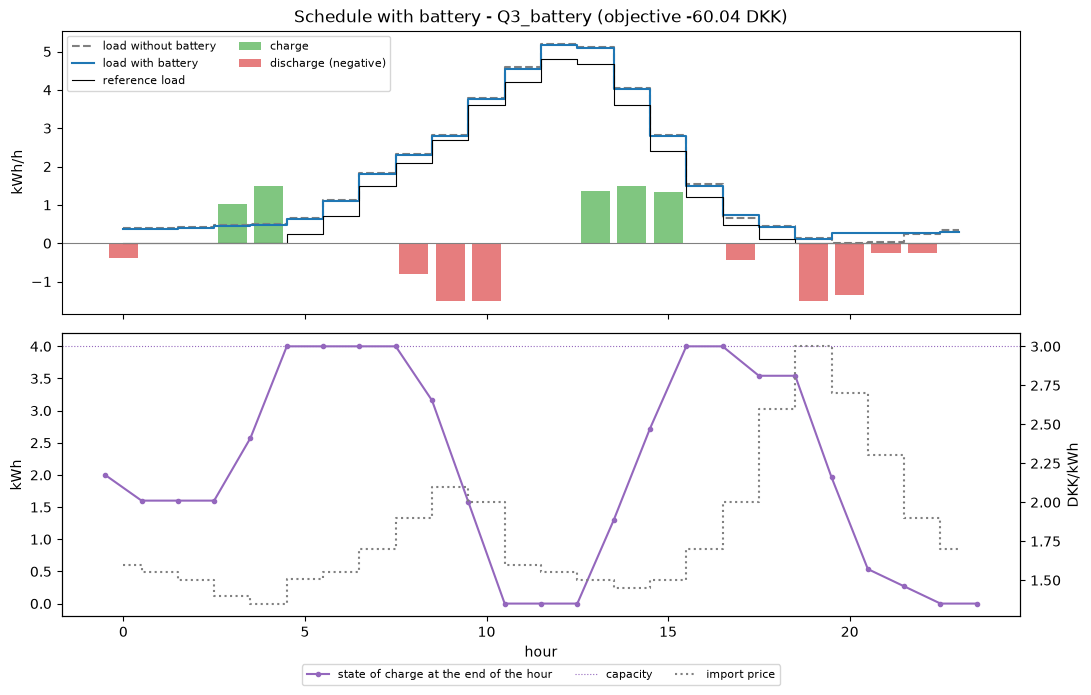

In [3]:
procurement_saving = wo.meta["procurement_cost"] - w.meta["procurement_cost"]
disutility_saving = disutility(hwo) - disutility(hw)
print(f"{procurement_saving:.3f} + {disutility_saving:.3f} + ({w.meta['terminal_value']:.3f}) = "
      f"{procurement_saving + disutility_saving + w.meta['terminal_value']:.3f}  (value of the battery)")
plot_battery_schedule(w, B, wo); plt.show()

**Hour by hour:** why does the load barely change? At an interior optimum
$\ell_t = \hat\ell_t + (\mu^E - \lambda_t)/(2c^Q)$, so the load only moves where $\lambda_t$ (dual of the balance)
or $\mu^E$ changes.

In [4]:
hours = pd.DataFrame({
    "p_imp": p_imp, "ref": hw["reference_load"],
    "load without": hwo["load"], "load with": hw["load"], "d_load": hw["load"] - hwo["load"],
    "lambda without": hwo["dual_balance"], "lambda with": hw["dual_balance"],
    "charge": hw["charge"], "discharge": hw["discharge"], "soc": hw["soc"],
    "export without": hwo["export"], "export with": hw["export"],
})
print("Sum of |d_load| =", round(hours["d_load"].abs().sum(), 3), "kWh")
hours.round(3)

Sum of |d_load| = 1.132 kWh


,p_imp,ref,load without,load with,d_load,lambda without,lambda with,charge,discharge,soc,export without,export with
hour,,,,,,,,,,,,
0,1.60,0.00,0.384,0.379,-0.005,1.60,1.551,0.000,0.379,1.601,-0.000,0.000
1,1.55,0.00,0.409,0.380,-0.030,1.55,1.550,0.000,0.000,1.601,-0.000,0.000
2,1.50,0.00,0.434,0.405,-0.030,1.50,1.500,0.000,0.000,1.601,-0.000,0.000
3,1.40,0.00,0.484,0.455,-0.030,1.40,1.400,1.025,0.000,2.575,-0.000,0.000
4,1.35,0.00,0.509,0.480,-0.030,1.35,1.350,1.500,0.000,4.000,-0.000,0.000
5,1.51,0.24,0.669,0.640,-0.030,1.51,1.510,0.000,0.000,4.000,0.000,0.000
6,1.55,0.72,1.129,1.100,-0.030,1.55,1.550,0.000,0.000,4.000,0.000,0.000
7,1.70,1.50,1.834,1.805,-0.030,1.70,1.700,0.000,0.000,4.000,0.000,0.000
8,1.90,2.10,2.334,2.305,-0.030,1.90,1.900,0.000,0.800,3.158,0.000,0.000


## 2. (v) Sensitivity sweeps

The sweeps of `main.py` (`Q3_BATTERY_SWEEPS`): one parameter at a time, the rest at the base case.
`battery_run` solves with and without the battery on the same data.

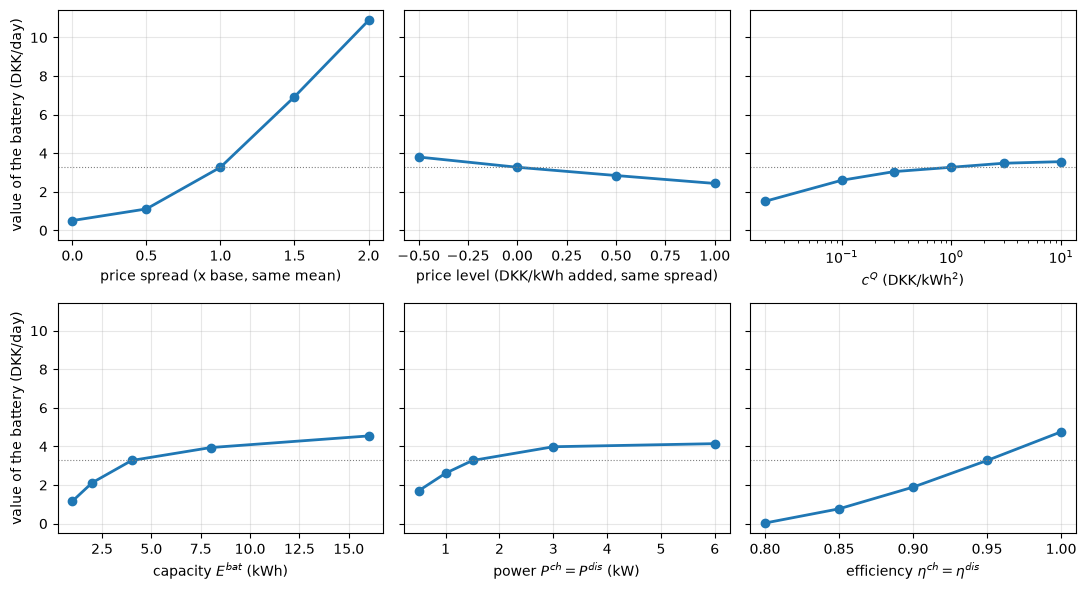

,parameter,value,value_DKK,pi_end,final_soc_kWh,discharged_kWh,overlap_max
0,price_spread,0.00,0.510,1.690,0.573,3.208,0.0
1,price_spread,0.50,1.113,1.647,0.694,5.481,0.0
2,price_spread,1.00,3.272,1.421,0.000,7.979,0.0
3,price_spread,1.50,6.926,1.195,0.000,8.408,0.0
4,price_spread,2.00,10.882,0.969,0.000,8.408,0.0
5,price_level,-0.50,3.803,0.895,0.000,8.407,0.0
6,price_level,0.00,3.272,1.421,0.000,7.979,0.0
7,price_level,0.50,2.844,1.947,0.000,7.600,0.0
8,price_level,1.00,2.434,2.474,0.000,7.600,0.0
9,c_Q,0.02,1.506,1.421,0.000,4.664,0.0


In [5]:
rows = []
for name, sw in Q3_BATTERY_SWEEPS.items():
    for v in sw["values"]:
        r = battery_run(sw["apply"](B, v))
        rows.append(dict(parameter=name, value=v, **{k: x for k, x in r.items() if k != "hourly"}))
sens = pd.DataFrame(rows)
plot_battery_sensitivity(sens, {n: sw["label"] for n, sw in Q3_BATTERY_SWEEPS.items()},
                         base_value=w.objective - wo.objective); plt.show()
sens.round(3)

**Try other values.** Change `name` and `values`, or build a scenario by hand with `src/scenarios.py`
(`scale_prices`, `shift_prices`, `roll_prices`, `set_tariffs`, `scale_pv`, `set_load_preferences`, `set_disutility`,
`set_battery`).

In [6]:
name, values = "capacity", [0.5, 1, 3, 4, 6, 10]
pd.DataFrame([dict(value=v, **{k: x for k, x in battery_run(Q3_BATTERY_SWEEPS[name]["apply"](B, v)).items()
                               if k != "hourly"}) for v in values]).round(3)

,value,value_DKK,pi_end,final_soc_kWh,discharged_kWh,overlap_max
0,0.5,0.623,1.421,0.0,1.598,0.0
1,1.0,1.165,1.421,0.0,2.784,0.0
2,3.0,2.769,1.421,0.0,6.079,0.0
3,4.0,3.272,1.421,0.0,7.979,0.0
4,6.0,3.735,1.421,0.0,9.761,0.0
5,10.0,4.100,1.421,0.0,11.095,0.0


## 3. End of the day

Every price-based alternative uses the same objective term, $+\pi^{end}(e_{23} - e^{init})$; only the number changes.

| alternative | $\pi^{end}$ |
|---|---|
| ours (i) | $\min\{\min_{night} p^{imp}_{D+1,t}/\eta^{ch},\ \eta^{dis}\max_t p^{imp}_{D+1,t}\}$ |
| trend | one-hour extrapolation: $p^{imp}_{23} + (p^{imp}_{23} - p^{imp}_{22})$ |
| last price | $p^{imp}_{23}$ |
| last price / $\eta^{ch}$ | $p^{imp}_{23}/\eta^{ch}$ (the cost of recharging in hour 23) |
| free end | $\pi^{end}=0$ |
| cyclic | $e_{23} \geq e^{init}$, no term |

This is `end_of_day_tables()` of `main.py`, the same table as `q3g_end_of_day.csv`. Two values of the battery:
- `value_reported_DKK`: what each objective says, with the stored energy valued at its own $\pi^{end}$;
- `value_exact_DKK`: the same operation of day D, with the stored energy valued with the exact curve $W(e_{23}) - W(e^{init})$
  of section 4. The benchmark row is the 35-hour solution itself.

"schedule_change" is the largest change of charging or discharging in any hour of day D compared with ours (kWh/h).

In [7]:
ends, water, pi_sweep = end_of_day_tables(B)
ref = battery_run(B)
print(f"p_imp_22 = {p_imp[22]:.2f}, p_imp_23 = {p_imp[23]:.2f}; recharging in hour 23 costs p_imp_23/eta_ch = {p_imp[23]/eta_ch:.3f}")
print(f"Decisions change for pi_end >= {pi_sweep.loc[pi_sweep['schedule_change'] > 0.05, 'pi_end'].min():.2f}; "
      f"recharging in the last hour for pi_end >= {pi_sweep.loc[pi_sweep['charge_last_hour'] > 0.05, 'pi_end'].min():.2f}")
ends = ends.set_index("end")
ends.round(3)

p_imp_22 = 1.90, p_imp_23 = 1.70; recharging in hour 23 costs p_imp_23/eta_ch = 1.789
Decisions change for pi_end >= 1.71; recharging in the last hour for pi_end >= 1.79


,pi_end,final_soc_kWh,value_reported_DKK,value_exact_DKK,schedule_change
end,,,,,
ours,1.421,0.000,3.272,3.118,0.000
benchmark (35 h),NaN,0.000,NaN,3.118,0.006
trend,1.500,0.000,3.115,3.118,0.001
last price,1.700,0.000,2.715,3.118,0.006
last price / eta_ch,1.789,2.336,2.634,2.527,1.136
free end,0.000,0.000,6.115,3.118,0.003
cyclic,0.000,2.000,2.634,2.634,1.136


**Fine sweep of $\pi^{end}$**: where the decisions change (threshold) and how the value of the battery changes.
The dotted lines are the price-based alternatives of the table above.

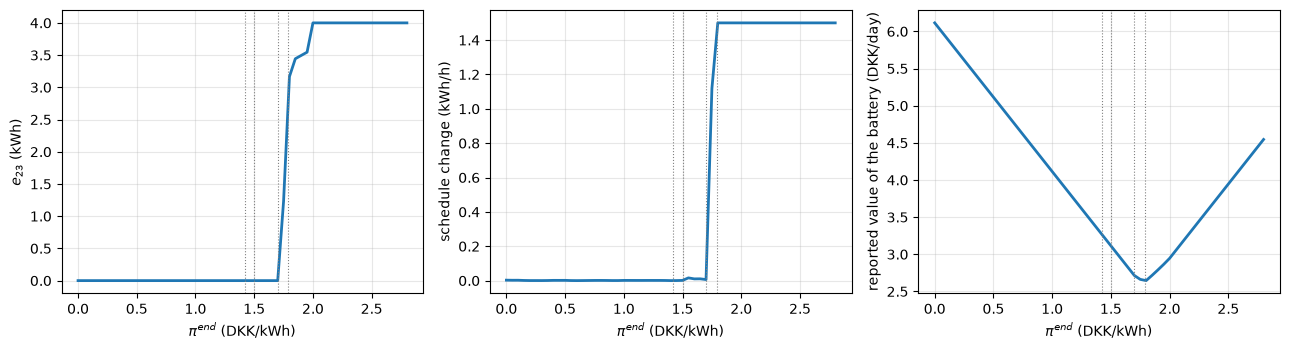

In [8]:
grid = np.round(np.arange(0.0, 2.81, 0.05), 2)
fine = []
for pe in grid:
    r = battery_run(B, pi_end=float(pe))
    fine.append(dict(pi_end=pe, final_soc=r["final_soc_kWh"], value_reported=r["value_DKK"],
                     schedule_change=schedule_change(r["hourly"], ref["hourly"])))
fine = pd.DataFrame(fine)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, col, lab in zip(axes, ["final_soc", "schedule_change", "value_reported"],
                        ["$e_{23}$ (kWh)", "schedule change (kWh/h)", "reported value of the battery (DKK/day)"]):
    ax.plot(fine["pi_end"], fine[col], color="C0", lw=2)
    for name, x in ends["pi_end"].dropna().items():
        if name not in ("free end", "cyclic"):
            ax.axvline(x, color="grey", lw=0.8, ls=":")
    ax.set(xlabel=r"$\pi^{end}$ (DKK/kWh)", ylabel=lab); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Extended-horizon benchmark (35 h)

The licence limits a QP to **200 variables**. The model of `src/model.py` has 7 variables per hour (load, PV,
import, export, charge, discharge, state of charge), so only 28 h would fit: up to 4 AM of D+1, before the morning peak.

`solve_extended_horizon()` (in `src/model.py`) writes the same problem in a compact form: the state of charge is an
expression, PV variables only exist in hours with PV, and the bounds are variable bounds. Day D plus hours 0-10 of D+1
(**35 h**, including the morning peak at hour 9) then fit in 196 variables. $E^{min}$ is imposed on day D only, and the
energy left at the end of the horizon has no value.

variables: 196 (limit 200)
e_23 in the benchmark: 0.0  | in our daily model: 0.0
schedule change on day D: 0.0062 kWh/h


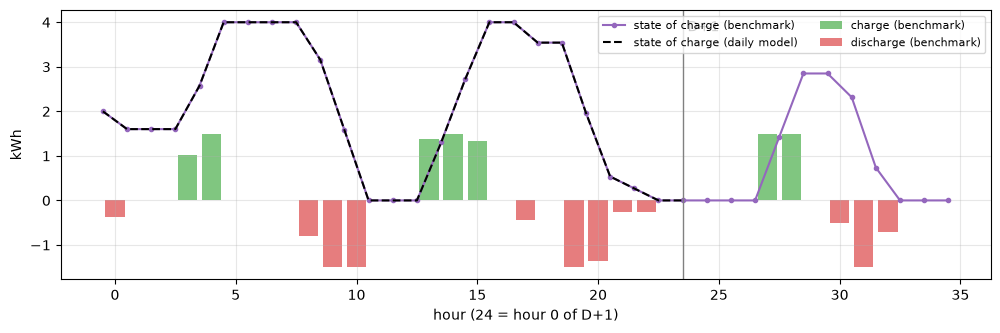

In [9]:
ext = solve_extended_horizon(B)
print("variables:", ext["n_variables"], "(limit 200)")
print("e_23 in the benchmark:", ext["soc"][23].round(3), " | in our daily model:", hw["soc"].iloc[-1].round(3))
print("schedule change on day D:", round(schedule_change(ext, hw), 4), "kWh/h")

h = np.arange(len(ext["soc"]))
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(h, ext["charge"], color="C2", alpha=0.6, label="charge (benchmark)")
ax.bar(h, -ext["discharge"], color="C3", alpha=0.6, label="discharge (benchmark)")
ax.plot(np.r_[-0.5, h + 0.5], np.r_[B.battery_initial_soc_kWh, ext["soc"]], color="C4", marker="o", ms=3,
        label="state of charge (benchmark)")
ax.plot(np.r_[-0.5, np.arange(24) + 0.5], np.r_[B.battery_initial_soc_kWh, hw["soc"]], color="k", ls="--",
        label="state of charge (daily model)")
ax.axvline(23.5, color="grey", lw=1); ax.text(23.7, 3.8, "D+1")
ax.set(xlabel="hour (24 = hour 0 of D+1)", ylabel="kWh"); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.show()

**Value of the stored energy (water value).** How much is it worth to start D+1 with $x$ kWh in the battery? Solve
only hours 0-10 of D+1 starting from $x$ and compare with starting empty. The slope is the value of the marginal kWh;
our $\pi^{end}$ is a single straight line. The exact values of section 3 replace the term
$\pi^{end}(e_{23} - e^{init})$ by $W(e_{23}) - W(e^{init})$.

Exact value of the battery: 3.118 DKK/day (reported: 3.272)


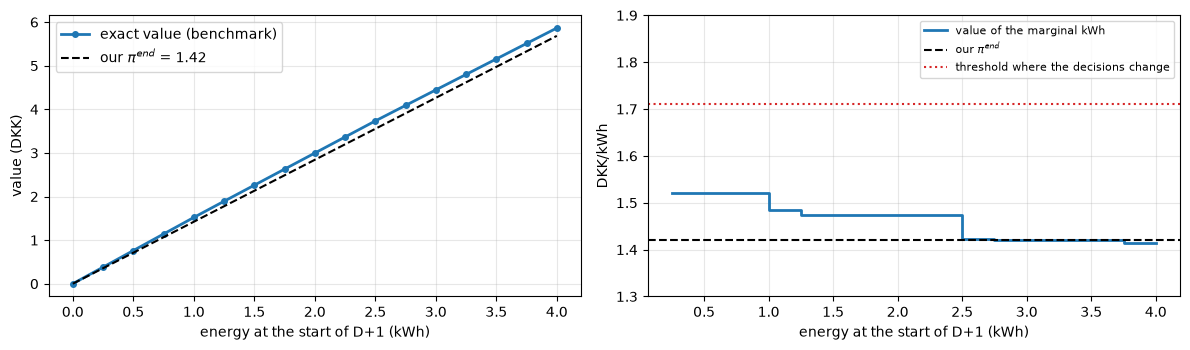

slopes: [1.52  1.52  1.52  1.52  1.484 1.474 1.474 1.474 1.474 1.474 1.423 1.421
 1.421 1.421 1.421 1.414] | mean over 4 kWh: 1.466


In [10]:
xs = np.arange(0, B.battery_capacity_kWh + 1e-9, 0.25)
W = np.array([solve_extended_horizon(B, today=False, start_soc=float(x))["objective"] for x in xs])
W -= W[0]
slope = np.diff(W) / np.diff(xs)
pi_end = terminal_value(B)
print(f"Exact value of the battery: {ends.loc['ours', 'value_exact_DKK']:.3f} DKK/day "
      f"(reported: {ends.loc['ours', 'value_reported_DKK']:.3f})")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
a1.plot(xs, W, color="C0", lw=2, marker="o", ms=4, label="exact value (benchmark)")
a1.plot(xs, pi_end * xs, color="k", ls="--", label=fr"our $\pi^{{end}}$ = {pi_end:.2f}")
a1.set(xlabel="energy at the start of D+1 (kWh)", ylabel="value (DKK)"); a1.legend(); a1.grid(alpha=0.3)
a2.step(xs[1:], slope, where="pre", color="C0", lw=2, label="value of the marginal kWh")
a2.axhline(pi_end, color="k", ls="--", label=r"our $\pi^{end}$")
a2.axhline(1.71, color="C3", ls=":", label="threshold where the decisions change")
a2.set(xlabel="energy at the start of D+1 (kWh)", ylabel="DKK/kWh", ylim=(1.3, 1.9)); a2.legend(fontsize=8)
a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("slopes:", slope.round(3), "| mean over 4 kWh:", round(W[-1] / 4, 3))

## 5. Notes

- What convinces me:
- What I want to change in the text of (iv)/(v):
- What to add to the report (and therefore to `main.py`):